# ESS 배터리 수명 예측 - DAY1 EDA

이 노트북은 과제의 다섯 가지 질문을 순서대로 직접 실행하고 결과를 확인하기 위한 학습용 버전입니다.  
각 셀을 `Shift + Enter`로 하나씩 실행하세요.

In [1]:
# 0. 환경 설정
import os, sys
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR', '/tmp/da_mpl_cache')

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / 'src' / 'day1_eda.py').exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy import stats
from IPython.display import display

from src.day1_eda import (
    BATCH_FILES, COLORS, load_batches, batch_summary,
    feature_correlations, policy_summary, within_batch_correlations
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
print('프로젝트 폴더:', ROOT)
print('Python:', sys.executable)

프로젝트 폴더: /Users/jiyong/Desktop/DA
Python: /Users/jiyong/Desktop/DA/.venv311/bin/python


## 1. 데이터 불러오기
MAT 파일에서 139개 셀의 Cycle Life, 사이클 요약값, Cycle 10·100의 Qdlin을 읽습니다. 

In [3]:
df, curves, voltage_grids = load_batches()
print(f'전체 셀: {len(df)}개')
print(f'Cycle Life 유효: {df.cycle_life.notna().sum()}개')
display(df.head())

전체 셀: 139개
Cycle Life 유효: 129개


,batch,cell_id,cell_index,cycle_life,log_cycle_life,policy,first_c_rate,n_recorded_cycles,knee_cycle,qd_10,...,mean_chargetime_100,dq_mean,dq_min,dq_max,dq_var,dq_log_var,dq_range,dq_skew,dq_kurtosis,knee_fraction
0,Batch 1,Batch1_C01,1,1190.0,7.081709,3.6C(80%)-3.6C,3.6,1189,878.0,1.074537,...,13.250388,-0.002873,-0.008460,0.000768,0.000010,-5.014861,0.009228,-0.532058,-1.348312,0.737815
1,Batch 1,Batch1_C02,2,1179.0,7.072422,3.6C(80%)-3.6C,3.6,1178,476.0,1.079777,...,13.240949,-0.004100,-0.011004,-0.000088,0.000010,-5.013960,0.010916,-0.429375,-1.029116,0.403732
2,Batch 1,Batch1_C03,3,1177.0,7.070724,3.6C(80%)-3.6C,3.6,1176,712.0,1.083782,...,13.245097,-0.004487,-0.017216,0.000013,0.000018,-4.737000,0.017229,-1.080194,0.348637,0.604928
3,Batch 1,Batch1_C04,4,1226.0,7.111512,4C(80%)-4C,4.0,1225,931.0,1.084308,...,11.932744,-0.007456,-0.018961,0.000182,0.000036,-4.442613,0.019143,-0.439050,-1.095416,0.759380
4,Batch 1,Batch1_C05,5,1227.0,7.112327,4C(80%)-4C,4.0,1226,928.0,1.081954,...,11.932781,-0.005750,-0.013958,0.000046,0.000023,-4.647744,0.014004,-0.362548,-1.333831,0.756316


In [4]:
# Target 결측 셀 확인: 지도학습과 Target 기반 EDA에서는 제외 대상
# 현재 용량이 초기 용량 * 0.8보다 작은 값이 있는지 확인한다.
missing = df[df.cycle_life.isna()][['batch', 'cell_id', 'policy', 'n_recorded_cycles']]
display(missing)
print('Target 결측:', len(missing), '개')

,batch,cell_id,policy,n_recorded_cycles
68,Batch 2,Batch2_C23,VarCharge-2C-100cycles,920
69,Batch 2,Batch2_C24,VarCharge-4C-100cycles,1152
81,Batch 2,Batch2_C36,VarCharge-6C-100cycles,423
82,Batch 2,Batch2_C37,VarCharge-8C-100cycles,280
83,Batch 2,Batch2_C38,3.6C(80%)-3.6C(SLOWCYCLE,101
84,Batch 2,Batch2_C39,4.8C(80%)-4.8C(SLOWCYCLE,101
85,Batch 2,Batch2_C40,3.6C(9%)-5C(SLOWCYCLE,434
86,Batch 2,Batch2_C41,5.2C(58%)-4C(SLOWCYCLE,459
116,Batch 3,Batch3_C24,4.8C(80%)-4.8C-newstructure,2189
125,Batch 3,Batch3_C33,4.8C(80%)-4.8C-newstructure,2237


Target 결측: 10 개


### 1-1. 데이터 품질 점검
본격적인 EDA 전에 열 이름·자료형·결측치·무한대와 사이클 배열 길이를 확인합니다. 여기서는 값을 제거하지 않고, 이후 분석에 사용할 수 있는 상태인지 진단만 합니다.

In [5]:
# 열 단위 구조 및 품질 확인
column_quality = pd.DataFrame({
    'column': df.columns,
    'dtype': [str(df[c].dtype) for c in df.columns],
    'type_group': ['numeric' if pd.api.types.is_numeric_dtype(df[c]) else 'text/category' for c in df.columns],
    'missing_n': [int(df[c].isna().sum()) for c in df.columns],
    'missing_pct': [df[c].isna().mean() * 100 for c in df.columns],
    'infinite_n': [int(np.isinf(pd.to_numeric(df[c], errors='coerce')).sum())
                   if pd.api.types.is_numeric_dtype(df[c]) else 0 for c in df.columns],
})

print(f'행(배터리 셀): {df.shape[0]}개 / 열: {df.shape[1]}개')
print('중복 cell_id:', int(df['cell_id'].duplicated().sum()), '개')
print('무한대가 있는 숫자형 열:', int((column_quality['infinite_n'] > 0).sum()), '개')
with pd.option_context('display.max_rows', None):
    display(column_quality.round({'missing_pct': 2}))

행(배터리 셀): 139개 / 열: 34개
중복 cell_id: 0 개
무한대가 있는 숫자형 열: 0 개


,column,dtype,type_group,missing_n,missing_pct,infinite_n
0,batch,str,text/category,0,0.00,0
1,cell_id,str,text/category,0,0.00,0
2,cell_index,int64,numeric,0,0.00,0
3,cycle_life,float64,numeric,10,7.19,0
4,log_cycle_life,float64,numeric,10,7.19,0
5,policy,str,text/category,0,0.00,0
6,first_c_rate,float64,numeric,0,0.00,0
7,n_recorded_cycles,int64,numeric,0,0.00,0
8,knee_cycle,float64,numeric,2,1.44,0
9,qd_10,float64,numeric,0,0.00,0


In [6]:
# 셀마다 사이클 축을 공유해야 하는 배열들의 길이 확인
cycle_signals = ['qd', 'ir', 'tavg', 'tmax', 'chargetime']
array_rows = []
for _, row in df.iterrows():
    signal_lengths = {name: len(curves[row.cell_id][name]) for name in cycle_signals}
    dq_points = int(np.isfinite(curves[row.cell_id]['dq']).sum())
    array_rows.append({
        'batch': row.batch,
        'cell_id': row.cell_id,
        **{f'{name}_len': length for name, length in signal_lengths.items()},
        'cycle_lengths_match': len(set(signal_lengths.values())) == 1,
        'matches_n_recorded_cycles': all(length == row.n_recorded_cycles for length in signal_lengths.values()),
        'dq_finite_voltage_points': dq_points,
        'dq_matches_voltage_grid': dq_points == len(voltage_grids[row.batch]),
    })

array_quality = pd.DataFrame(array_rows)
problem_arrays = array_quality[
    ~array_quality['cycle_lengths_match']
    | ~array_quality['matches_n_recorded_cycles']
    | ~array_quality['dq_matches_voltage_grid']
]

display(array_quality.groupby('batch').agg(
    cells=('cell_id', 'size'),
    cycle_length_mismatch=('cycle_lengths_match', lambda x: int((~x).sum())),
    recorded_cycle_mismatch=('matches_n_recorded_cycles', lambda x: int((~x).sum())),
    dq_grid_mismatch=('dq_matches_voltage_grid', lambda x: int((~x).sum())),
))
print('점검이 필요한 셀:', len(problem_arrays), '개')
if len(problem_arrays):
    display(problem_arrays)
else:
    print('모든 셀의 사이클 배열 길이와 ΔQ(V) 전압 격자가 일치합니다.')

,cells,cycle_length_mismatch,recorded_cycle_mismatch,dq_grid_mismatch
batch,,,,
Batch 1,46,0,0,0
Batch 2,47,0,0,0
Batch 3,46,0,0,0


점검이 필요한 셀: 0 개
모든 셀의 사이클 배열 길이와 ΔQ(V) 전압 격자가 일치합니다.


## Q1. Cycle Life 분포는 어떻게 생겼는가?
Batch별 중앙값, 장수명(>1,000), 단수명(<500) 비율과 분포 차이를 확인합니다.

,batch,cells_total,target_valid,target_missing,cycle_life_mean,cycle_life_median,cycle_life_min,cycle_life_max,short_lt_500_n,short_lt_500_pct,long_gt_1000_n,long_gt_1000_pct,knee_median,knee_fraction_median
0,Batch 1,46,46,0,844.72,858.5,534.0,1227.0,0,0.00,10,21.74,610.5,0.73
1,Batch 2,47,39,8,565.74,472.0,392.0,1186.0,28,71.79,3,7.69,353.0,0.78
2,Batch 3,46,44,2,1059.66,1005.5,541.0,1935.0,0,0.00,23,52.27,785.0,0.76


/var/folders/mc/z9s4pxn91wbb6b7z04d9d46c0000gn/T/ipykernel_22969/1530123808.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, col].boxplot(values, vert=False, patch_artist=True, boxprops={'facecolor': COLORS[batch], 'alpha': .65})
/var/folders/mc/z9s4pxn91wbb6b7z04d9d46c0000gn/T/ipykernel_22969/1530123808.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, col].boxplot(values, vert=False, patch_artist=True, boxprops={'facecolor': COLORS[batch], 'alpha': .65})
/var/folders/mc/z9s4pxn91wbb6b7z04d9d46c0000gn/T/ipykernel_22969/1530123808.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, col].boxplot(values, vert=False, patch_a

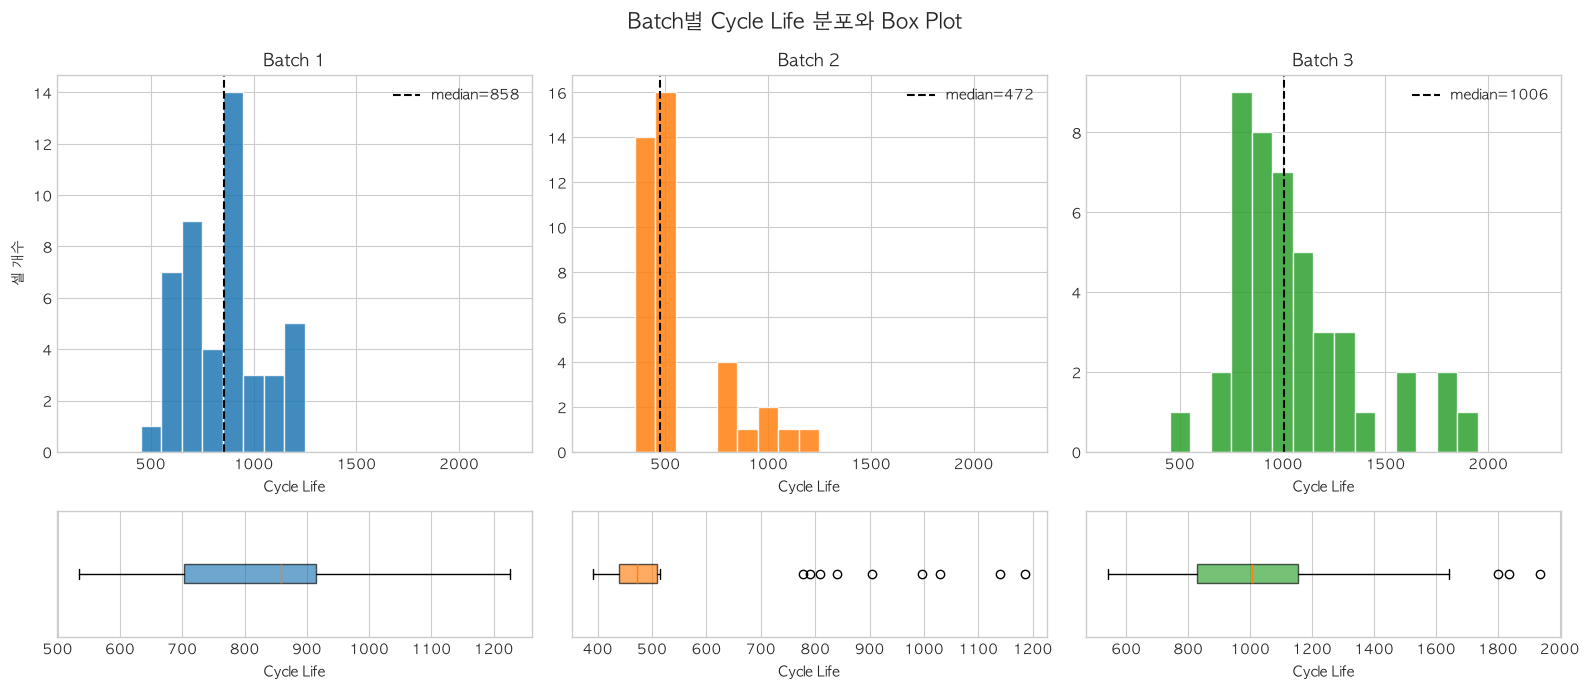

,batch,cell_id,cycle_life,outlier_direction,first_c_rate,policy,iqr_lower,iqr_upper
0,Batch 2,Batch2_C08,777.0,장수명,4.8,4.8C(80%)-4.8C-newstructure,336.00,612.00
2,Batch 2,Batch2_C10,791.0,장수명,5.6,5.6C(26%)-4.5C-newstructure,336.00,612.00
3,Batch 2,Batch2_C33,809.0,장수명,4.8,4.8C(80%)-4.8C-newstructure,336.00,612.00
7,Batch 2,Batch2_C45,841.0,장수명,5.2,5.2C(58%)-4C-newstructure,336.00,612.00
1,Batch 2,Batch2_C09,904.0,장수명,5.2,5.2C(58%)-4C-newstructure,336.00,612.00
8,Batch 2,Batch2_C46,997.0,장수명,5.6,5.6C(26%)-4.5C-newstructure,336.00,612.00
6,Batch 2,Batch2_C44,1029.0,장수명,4.8,4.8C(80%)-4.8C-newstructure,336.00,612.00
4,Batch 2,Batch2_C34,1140.0,장수명,5.2,5.2C(58%)-4C-newstructure,336.00,612.00
5,Batch 2,Batch2_C35,1186.0,장수명,5.6,5.6C(26%)-4.5C-newstructure,336.00,612.00
11,Batch 3,Batch3_C46,1801.0,장수명,4.8,4.8C(80%)-4.8C-newstructure,337.12,1646.12


In [7]:
summary = batch_summary(df)
display(summary.round(2))

fig, axes = plt.subplots(2, 3, figsize=(16, 7), gridspec_kw={'height_ratios': [3, 1]})
# 과제 지시 범위: 150~2,300사이클
bins = np.arange(150, 2301, 100)
for col, batch in enumerate(BATCH_FILES):
    values = df.loc[df.batch == batch, 'cycle_life'].dropna()
    axes[0, col].hist(values, bins=bins, color=COLORS[batch], edgecolor='white', alpha=.85)
    axes[0, col].axvline(values.median(), color='black', linestyle='--', label=f'median={values.median():.0f}')
    axes[0, col].set(title=batch, xlabel='Cycle Life')
    axes[0, col].legend()
    axes[1, col].boxplot(values, vert=False, patch_artist=True, boxprops={'facecolor': COLORS[batch], 'alpha': .65})
    axes[1, col].set(xlabel='Cycle Life', yticks=[])
axes[0, 0].set_ylabel('셀 개수')
plt.suptitle('Batch별 Cycle Life 분포와 Box Plot', fontsize=15)
plt.tight_layout(); plt.show()

# IQR(1.5×IQR) 기준 이상치 셀과 충전정책 확인
outlier_rows = []
for batch, group in df[df.cycle_life.notna()].groupby('batch', sort=False):
    q1, q3 = group.cycle_life.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = group[(group.cycle_life < lower) | (group.cycle_life > upper)].copy()
    flagged['outlier_direction'] = np.where(flagged.cycle_life < lower, '단수명', '장수명')
    flagged['iqr_lower'] = lower
    flagged['iqr_upper'] = upper
    outlier_rows.append(flagged)

cycle_life_outliers = pd.concat(outlier_rows, ignore_index=True)
display(cycle_life_outliers[
    ['batch', 'cell_id', 'cycle_life', 'outlier_direction', 'first_c_rate', 'policy', 'iqr_lower', 'iqr_upper']
].sort_values(['batch', 'cycle_life']).round(2))

**해석 및 전처리 주의사항**
- IQR 이상치는 통계적으로 분포에서 먼 셀이라는 뜻이며, 곧바로 오류로 간주해 삭제하지 않습니다. 충전정책과 원시 열화곡선을 함께 확인해야 합니다.
- 현재 분포는 Batch 1·2·3 원본 139개 셀을 보여줍니다. Cycle Life가 없는 10개 셀은 Target 기반 분석에서 제외합니다.
- 원논문 처리 코드는 수집 문제·비정상 종료용량·미완료 셀을 추가로 제외하므로, 모델링 전에는 공식 제외 기준에 따른 민감도 분석이 필요합니다.
- Batch 2가 500사이클 미만에 집중되고 Batch 3은 장수명 쪽으로 이동하므로, Batch 1만 학습하면 Batch 2·3에서 분포 이동에 따른 일반화 저하가 발생할 수 있습니다.

## Q2. 방전용량은 어떻게 감소하며 Knee Point는 언제 나타나는가?
위 행은 원데이터 `QDischarge(Ah)`와 데이터셋의 명목 EOL 기준 0.88 Ah를, 아래 행은 초기 안정 구간(2~6사이클) 중앙값으로 정규화한 `QD retention`을 보여줍니다. 정규화 0.8은 과제의 SOH 80% 참고선이며, 데이터셋의 Cycle Life는 공식 처리상 0.88 Ah 기준 또는 마지막 기록+1로 저장될 수 있으므로 두 기준을 구분해 해석합니다.

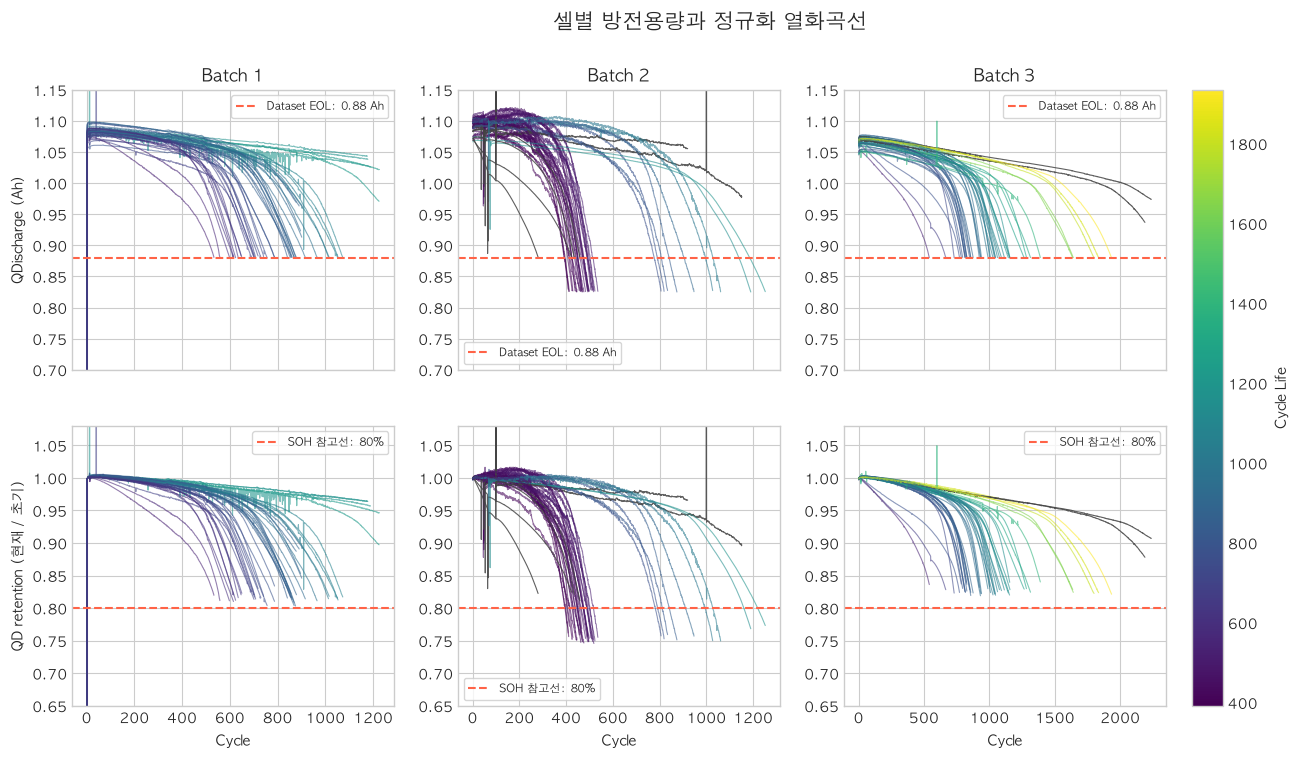

,cells,valid_cycle_life,eol_088_observed_at_end,target_last_plus_one
batch,,,,
Batch 1,46,46,0,46
Batch 2,47,39,39,0
Batch 3,46,44,0,44


,batch,knee_median,knee_fraction_median
0,Batch 1,610.5,0.734
1,Batch 2,353.0,0.775
2,Batch 3,785.0,0.765


In [8]:
# 전체 Batch에 동일한 색상 기준을 적용: 보라색=단수명, 노란색=장수명
valid_life = df['cycle_life'].dropna()
life_norm = Normalize(vmin=valid_life.min(), vmax=valid_life.max())
life_cmap = plt.colormaps['viridis']

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex='col')
for col, batch in enumerate(BATCH_FILES):
    ax_qd, ax_ret = axes[0, col], axes[1, col]
    subset = df[df.batch == batch]
    for _, row in subset.iterrows():
        qd = np.asarray(curves[row.cell_id]['qd'], dtype=float)
        # 첫 사이클의 0 또는 이상값 영향을 피하기 위해 2~6사이클 중앙값 사용
        initial_capacity = np.nanmedian(qd[1:min(6, len(qd))])
        if not np.isfinite(initial_capacity) or initial_capacity <= 0:
            continue
        qd_retention = qd / initial_capacity
        has_life = pd.notna(row.cycle_life)
        line_color = life_cmap(life_norm(row.cycle_life)) if has_life else '#444444'
        cycles = np.arange(1, len(qd) + 1)
        alpha = .58 if has_life else .85
        ax_qd.plot(cycles, qd, color=line_color, alpha=alpha, linewidth=.8)
        ax_ret.plot(cycles, qd_retention, color=line_color, alpha=alpha, linewidth=.8)
    ax_qd.axhline(.88, color='tomato', linestyle='--', linewidth=1.5, label='Dataset EOL: 0.88 Ah')
    ax_ret.axhline(.80, color='tomato', linestyle='--', linewidth=1.5, label='SOH 참고선: 80%')
    ax_qd.set(title=batch, ylim=(.70, 1.15))
    ax_ret.set(xlabel='Cycle', ylim=(.65, 1.08))
    ax_qd.legend(loc='best', frameon=True, fontsize=8)
    ax_ret.legend(loc='best', frameon=True, fontsize=8)

axes[0, 0].set_ylabel('QDischarge (Ah)')
axes[1, 0].set_ylabel('QD retention (현재 / 초기)')
colorbar = fig.colorbar(ScalarMappable(norm=life_norm, cmap=life_cmap), ax=axes, pad=.02)
colorbar.set_label('Cycle Life')
fig.suptitle('셀별 방전용량과 정규화 열화곡선', fontsize=15)
plt.show()

# 공식 처리에서 마지막 QD가 0.88 Ah 이상이면 Cycle Life가 마지막 기록+1로 저장될 수 있음
eol_rows = []
for _, row in df.iterrows():
    qd = np.asarray(curves[row.cell_id]['qd'], dtype=float)
    end_qd = qd[np.flatnonzero(np.isfinite(qd))[-1]]
    eol_rows.append({
        'batch': row.batch, 'cell_id': row.cell_id, 'end_qd': end_qd,
        'cycle_life': row.cycle_life, 'n_recorded_cycles': len(qd),
        'eol_088_observed_at_end': end_qd < .88,
        'target_is_last_plus_one': pd.notna(row.cycle_life) and np.isclose(row.cycle_life, len(qd) + 1),
    })
eol_check = pd.DataFrame(eol_rows)
display(eol_check.groupby('batch').agg(
    cells=('cell_id', 'size'),
    valid_cycle_life=('cycle_life', 'count'),
    eol_088_observed_at_end=('eol_088_observed_at_end', 'sum'),
    target_last_plus_one=('target_is_last_plus_one', 'sum'),
))
display(summary[['batch', 'knee_median', 'knee_fraction_median']].round(3))

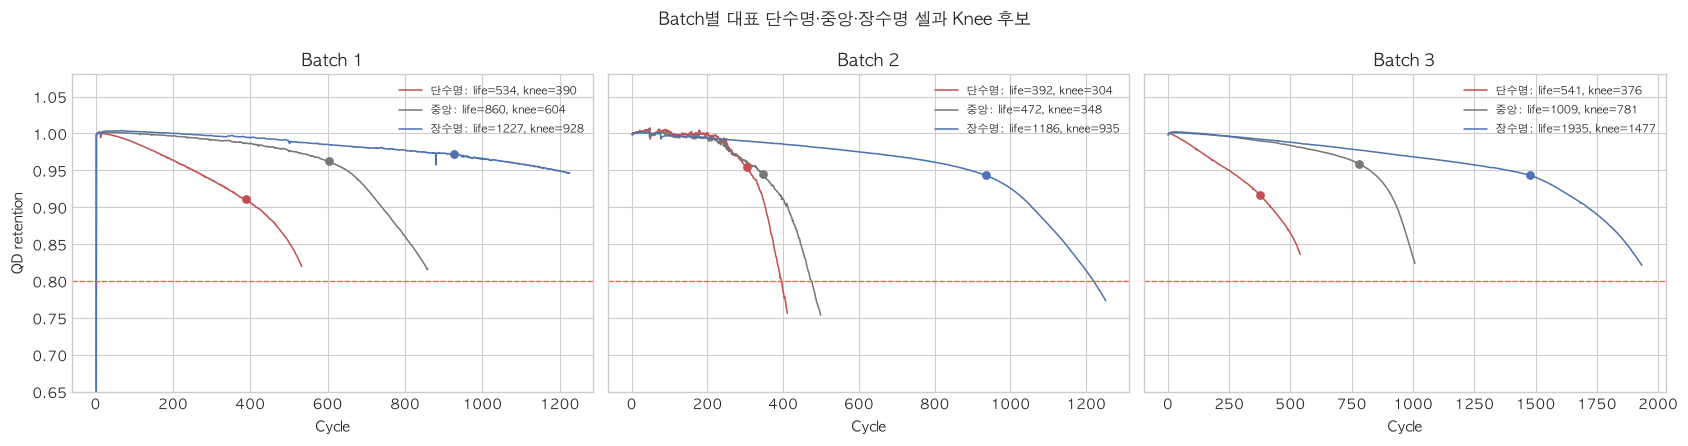

,batch,group,cell_id,cycle_life,knee_cycle,knee_fraction
0,Batch 1,단수명,Batch1_C21,534.0,390.0,0.730
1,Batch 1,중앙,Batch1_C29,860.0,604.0,0.702
2,Batch 1,장수명,Batch1_C05,1227.0,928.0,0.756
3,Batch 2,단수명,Batch2_C20,392.0,304.0,0.776
4,Batch 2,중앙,Batch2_C17,472.0,348.0,0.737
5,Batch 2,장수명,Batch2_C35,1186.0,935.0,0.788
6,Batch 3,단수명,Batch3_C29,541.0,376.0,0.695
7,Batch 3,중앙,Batch3_C01,1009.0,781.0,0.774
8,Batch 3,장수명,Batch3_C39,1935.0,1477.0,0.763


,cells,pre_knee_slope,post_knee_slope,acceleration_ratio
batch,,,,
Batch 1,46,-0.690,-6.260,8.429
Batch 2,39,-1.860,-14.425,8.025
Batch 3,44,-0.581,-5.610,8.738


In [9]:
# 각 Batch의 단수명·중앙수명·장수명 대표 셀을 동일한 방식으로 비교
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
representative_rows = []
for ax, batch in zip(axes, BATCH_FILES):
    subset = df[(df.batch == batch) & df.cycle_life.notna()].sort_values('cycle_life')
    picks = [subset.iloc[0], subset.iloc[len(subset)//2], subset.iloc[-1]]
    for row, label, color in zip(picks, ['단수명', '중앙', '장수명'], ['#c44e52', '#777777', '#4c72b0']):
        qd = np.asarray(curves[row.cell_id]['qd'], dtype=float)
        initial_capacity = np.nanmedian(qd[1:min(6, len(qd))])
        retention = qd / initial_capacity
        cycles = np.arange(1, len(retention) + 1)
        ax.plot(cycles, retention, color=color, linewidth=1.1,
                label=f'{label}: life={row.cycle_life:.0f}, knee={row.knee_cycle:.0f}')
        if pd.notna(row.knee_cycle) and 1 <= int(row.knee_cycle) <= len(retention):
            k = int(row.knee_cycle) - 1
            ax.scatter(k + 1, retention[k], color=color, s=28, zorder=3)
        representative_rows.append({
            'batch': batch, 'group': label, 'cell_id': row.cell_id,
            'cycle_life': row.cycle_life, 'knee_cycle': row.knee_cycle,
            'knee_fraction': row.knee_fraction,
        })
    ax.axhline(.80, color='tomato', linestyle='--', linewidth=1)
    ax.set(title=batch, xlabel='Cycle', ylim=(.65, 1.08))
    ax.legend(fontsize=8)
axes[0].set_ylabel('QD retention')
fig.suptitle('Batch별 대표 단수명·중앙·장수명 셀과 Knee 후보')
plt.tight_layout(); plt.show()
display(pd.DataFrame(representative_rows).round(3))

# 열화 속도가 Knee 이후 빨라지는지 정량 확인
def retention_slope_pct_per_100(y, start, stop):
    start, stop = max(0, int(start)), min(len(y), int(stop))
    values = np.asarray(y[start:stop], dtype=float)
    x = np.arange(start, stop)
    mask = np.isfinite(values)
    if mask.sum() < 20:
        return np.nan
    # retention/cycle → 100사이클당 percentage point 변화
    return np.polyfit(x[mask], values[mask], 1)[0] * 100 * 100

degradation_rows = []
for _, row in df[df.cycle_life.notna() & df.knee_cycle.notna()].iterrows():
    qd = np.asarray(curves[row.cell_id]['qd'], dtype=float)
    initial_capacity = np.nanmedian(qd[1:min(6, len(qd))])
    retention = pd.Series(qd / initial_capacity).rolling(21, center=True, min_periods=1).median().to_numpy()
    knee = int(row.knee_cycle) - 1
    pre = retention_slope_pct_per_100(retention, 99, knee)
    post = retention_slope_pct_per_100(retention, knee, len(retention))
    degradation_rows.append({
        'batch': row.batch, 'cell_id': row.cell_id,
        'pre_knee_slope_pp_per_100': pre,
        'post_knee_slope_pp_per_100': post,
        'acceleration_ratio': abs(post) / abs(pre) if np.isfinite(pre) and abs(pre) > 1e-8 else np.nan,
    })
degradation_speed = pd.DataFrame(degradation_rows)
display(degradation_speed.groupby('batch').agg(
    cells=('cell_id', 'size'),
    pre_knee_slope=('pre_knee_slope_pp_per_100', 'median'),
    post_knee_slope=('post_knee_slope_pp_per_100', 'median'),
    acceleration_ratio=('acceleration_ratio', 'median'),
).round(3))

## Q3. ΔQ(V)에서 초기 수명 차이가 보이는가?
Cycle 100의 방전용량 곡선에서 Cycle 10 곡선을 뺍니다. 더 크게 내려갈수록 초기 100사이클 동안 곡선이 많이 변했다는 뜻입니다. Batch 3의 Qdlin 수집 시작점 차이에 따른 왜곡을 줄이기 위해 세 Batch에 공통으로 존재하는 전압 범위만 표시하고, 통계 상관관계는 Batch 내부에서 계산합니다.

공통 전압 범위: 2.000~3.500 V


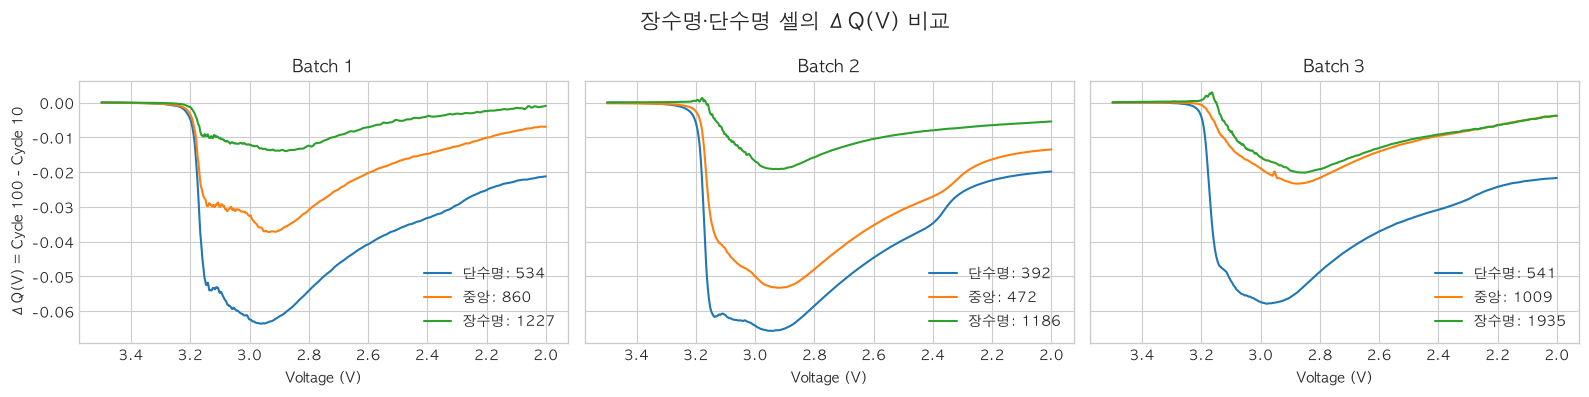

In [10]:
common_v_min = max(np.nanmin(v) for v in voltage_grids.values())
common_v_max = min(np.nanmax(v) for v in voltage_grids.values())
print(f'공통 전압 범위: {common_v_min:.3f}~{common_v_max:.3f} V')

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, batch in zip(axes, BATCH_FILES):
    subset = df[(df.batch == batch) & df.cycle_life.notna()].sort_values('cycle_life')
    picks = [subset.iloc[0], subset.iloc[len(subset)//2], subset.iloc[-1]]
    for row, label in zip(picks, ['단수명', '중앙', '장수명']):
        dq = curves[row.cell_id]['dq']
        v = voltage_grids[batch][:len(dq)]
        mask = np.isfinite(dq) & np.isfinite(v) & (v >= common_v_min) & (v <= common_v_max)
        ax.plot(v[mask], dq[mask], label=f'{label}: {row.cycle_life:.0f}')
    ax.invert_xaxis(); ax.set(title=batch, xlabel='Voltage (V)'); ax.legend()
axes[0].set_ylabel('ΔQ(V) = Cycle 100 - Cycle 10')
plt.suptitle('장수명·단수명 셀의 ΔQ(V) 비교', fontsize=15)
plt.tight_layout(); plt.show()

In [11]:
# ΔQ 통계값과 Cycle Life의 Batch별 상관관계
within_corr = within_batch_correlations(df)
dq_features = ['dq_log_var', 'dq_min', 'dq_mean', 'dq_range']
display(within_corr[within_corr.feature.isin(dq_features)].pivot(index='feature', columns='batch', values='spearman').round(3))

batch,Batch 1,Batch 2,Batch 3
feature,,,
dq_log_var,-0.871,-0.709,-0.797
dq_mean,0.828,0.697,0.756
dq_min,0.850,0.661,0.776
dq_range,-0.850,-0.650,-0.673


## Q4. 충전조건(C-rate)과 수명은 어떤 관계인가?
첫 단계 C-rate와 최종수명뿐 아니라 초기 QD 열화 기울기의 관계도 확인합니다. 다단계 충전 프로토콜은 첫 C-rate 하나로 완전히 표현할 수 없으므로 정책별 평균 수명과 표준편차를 함께 비교합니다. 상관관계가 인과관계를 의미하지는 않습니다.

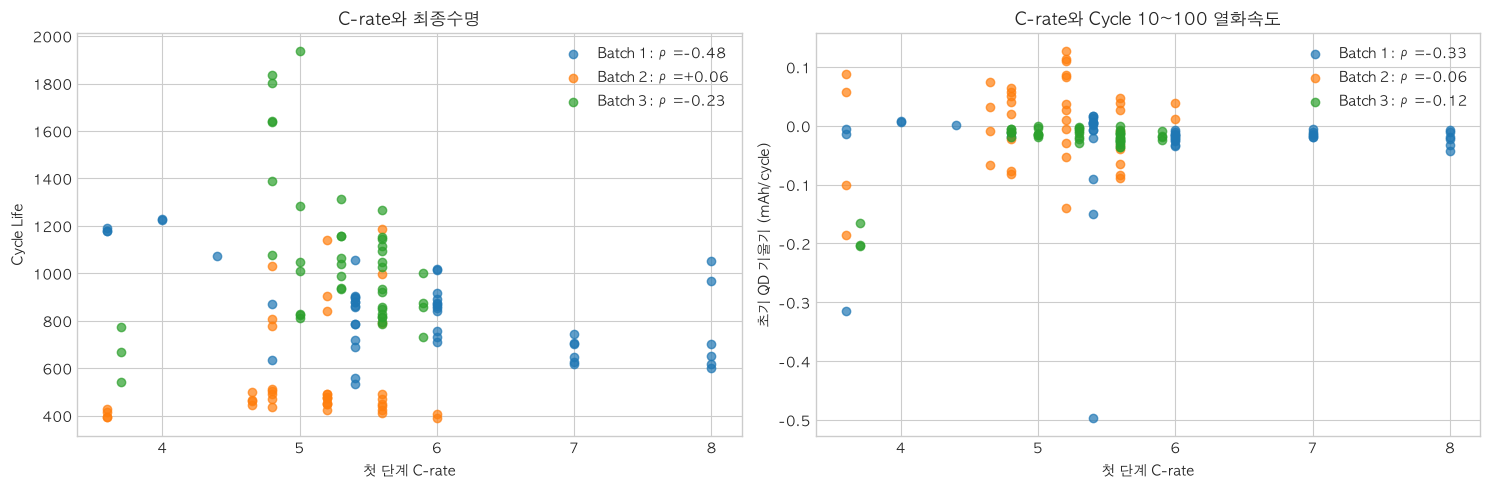

,batch,rho_vs_cycle_life,rho_vs_qd_slope_10_100
0,Batch 1,-0.483,-0.328
1,Batch 2,0.055,-0.064
2,Batch 3,-0.229,-0.123


,batch,policy,n,mean_life,std_life,median_life,first_c_rate
3,Batch 1,4C(80%)-4C,2,1226.50,0.71,1226.5,4.00
0,Batch 1,3.6C(80%)-3.6C,3,1182.00,7.00,1179.0,3.60
20,Batch 1,8C(15%)-3.6C,2,1008.50,60.10,1008.5,8.00
4,Batch 1,5.4C(40%)-3.6C,2,966.50,123.74,966.5,5.40
11,Batch 1,6C(30%)-3.6C,2,952.50,86.97,952.5,6.00
13,Batch 1,6C(40%)-3C,2,935.50,115.26,935.5,6.00
5,Batch 1,5.4C(50%)-3.6C,2,899.50,3.54,899.5,5.40
15,Batch 1,6C(50%)-3C,2,888.50,40.31,888.5,6.00
7,Batch 1,5.4C(60%)-3.6C,2,859.50,3.54,859.5,5.40
12,Batch 1,6C(40%)-3.6C,2,856.00,19.80,856.0,6.00


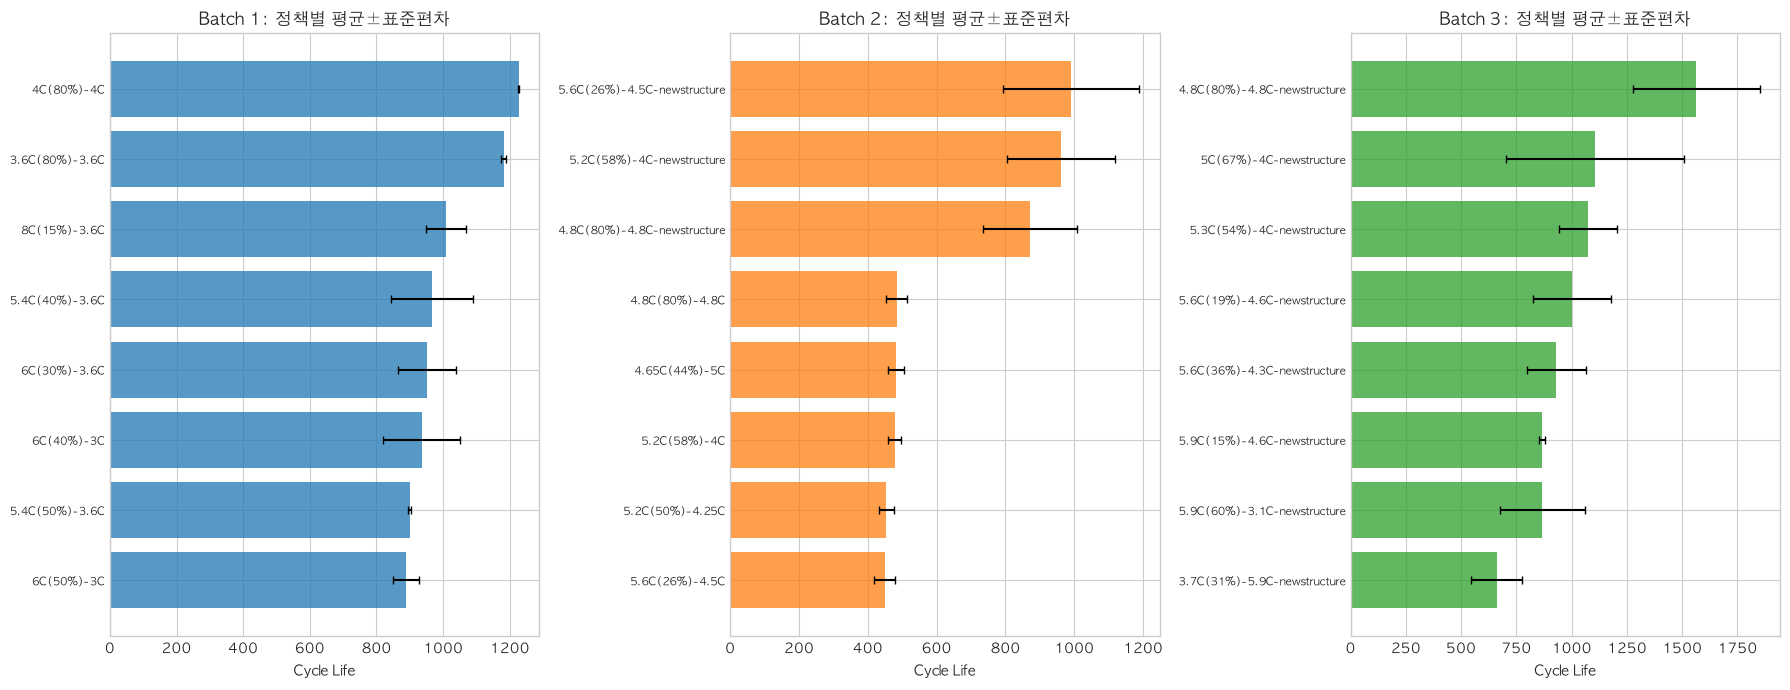

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
c_rate_rows = []
for batch in BATCH_FILES:
    g = df[(df.batch == batch) & df.cycle_life.notna()].copy()
    rho_life = stats.spearmanr(g.first_c_rate, g.cycle_life, nan_policy='omit').statistic
    rho_fade = stats.spearmanr(g.first_c_rate, g.qd_slope_10_100, nan_policy='omit').statistic
    axes[0].scatter(g.first_c_rate, g.cycle_life, alpha=.7,
                    label=f'{batch}: ρ={rho_life:+.2f}', color=COLORS[batch])
    axes[1].scatter(g.first_c_rate, g.qd_slope_10_100 * 1000, alpha=.7,
                    label=f'{batch}: ρ={rho_fade:+.2f}', color=COLORS[batch])
    c_rate_rows.append({'batch': batch, 'rho_vs_cycle_life': rho_life,
                        'rho_vs_qd_slope_10_100': rho_fade})
axes[0].set(xlabel='첫 단계 C-rate', ylabel='Cycle Life', title='C-rate와 최종수명')
axes[1].set(xlabel='첫 단계 C-rate', ylabel='초기 QD 기울기 (mAh/cycle)',
            title='C-rate와 Cycle 10~100 열화속도')
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(c_rate_rows).round(3))

policy = policy_summary(df)
policy_compare = policy[policy.n >= 2].copy()
display(policy_compare.sort_values(['batch', 'mean_life'], ascending=[True, False]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, batch in zip(axes, BATCH_FILES):
    # 표가 지나치게 복잡해지지 않도록 반복 셀이 있는 정책 중 표본 수가 큰 8개 표시
    g = policy_compare[policy_compare.batch == batch].nlargest(8, 'n').sort_values('mean_life')
    ax.barh(g.policy, g.mean_life, xerr=g.std_life.fillna(0),
            color=COLORS[batch], alpha=.75, capsize=3)
    ax.set(title=f'{batch}: 정책별 평균±표준편차', xlabel='Cycle Life')
    ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

## Q5. 어떤 초기 신호가 수명과 연관되는가?
Spearman 상관계수로 비선형 단조관계를 확인합니다. 전체 통합 상관계수만 보면 Batch 분포 차이가 신호처럼 보일 수 있으므로, 동일 피처의 Batch별 상관 방향과 크기도 함께 비교하고 상위 피처끼리의 중복성을 확인합니다.

,feature,n,spearman_vs_life,spearman_p,pearson_vs_log_life
20,dq_log_var,129,-0.8921,0.0000,-0.8864
18,dq_min,129,0.8834,0.0000,0.8880
17,dq_mean,129,0.8693,0.0000,0.8608
21,dq_range,129,-0.8683,0.0000,-0.8724
0,qd_10,129,-0.5274,0.0000,-0.5657
10,mean_qd_100,129,-0.4868,0.0000,-0.5684
1,qd_100,129,-0.4838,0.0000,-0.5153
23,dq_kurtosis,129,0.3773,0.0000,0.3234
12,mean_ir_100,129,-0.3464,0.0001,-0.0028
22,dq_skew,129,-0.3366,0.0001,-0.0937


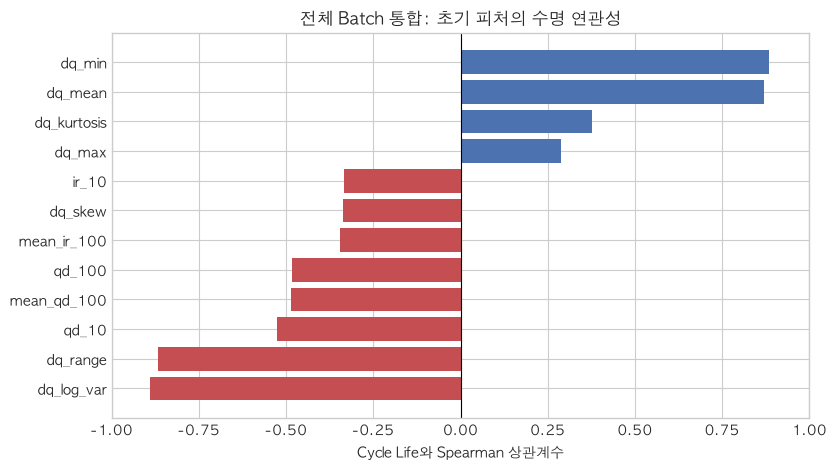

batch,Batch 1,Batch 2,Batch 3
feature,,,
dq_log_var,-0.871,-0.709,-0.797
dq_min,0.850,0.661,0.776
dq_mean,0.828,0.697,0.756
dq_range,-0.850,-0.650,-0.673
qd_10,0.100,0.077,0.130
mean_qd_100,0.185,0.112,0.162
qd_100,0.324,0.077,0.178
dq_kurtosis,0.219,0.500,0.320
mean_ir_100,0.136,-0.346,0.169


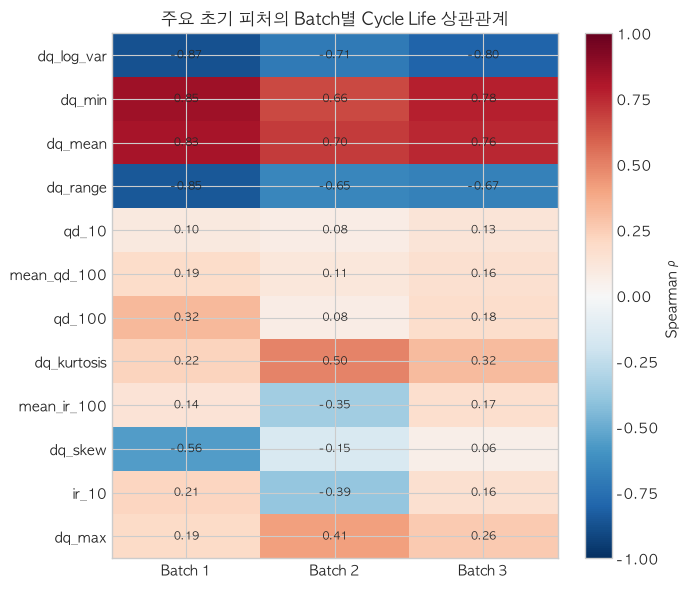

In [13]:
corr = feature_correlations(df)
display(corr[['feature', 'n', 'spearman_vs_life', 'spearman_p', 'pearson_vs_log_life']].round(4))

top = corr.head(12).sort_values('spearman_vs_life')
plt.figure(figsize=(9, 5))
plt.barh(top.feature, top.spearman_vs_life, color=['#c44e52' if x < 0 else '#4c72b0' for x in top.spearman_vs_life])
plt.axvline(0, color='black', linewidth=.8); plt.xlim(-1, 1)
plt.xlabel('Cycle Life와 Spearman 상관계수'); plt.title('전체 Batch 통합: 초기 피처의 수명 연관성'); plt.show()

# 같은 피처가 Batch 1·2·3에서도 일관된 관계를 보이는지 확인
within_all = within_batch_correlations(df)
batch_corr = within_all.pivot(index='feature', columns='batch', values='spearman')
compare_features = corr.head(12).feature.tolist()
batch_corr_top = batch_corr.reindex(compare_features)
display(batch_corr_top.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(batch_corr_top, vmin=-1, vmax=1, cmap='RdBu_r', aspect='auto')
ax.set_xticks(range(len(batch_corr_top.columns)), batch_corr_top.columns)
ax.set_yticks(range(len(batch_corr_top.index)), batch_corr_top.index)
for i in range(len(batch_corr_top.index)):
    for j in range(len(batch_corr_top.columns)):
        value = batch_corr_top.iloc[i, j]
        ax.text(j, i, '' if pd.isna(value) else f'{value:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax, label='Spearman ρ')
plt.title('주요 초기 피처의 Batch별 Cycle Life 상관관계')
plt.tight_layout(); plt.show()

,dq_log_var,dq_min,dq_mean,dq_range,qd_10,mean_qd_100,qd_100,dq_kurtosis
dq_log_var,1.00,-0.98,-0.98,0.97,0.48,0.38,0.40,-0.39
dq_min,-0.98,1.00,0.98,-0.97,-0.51,-0.41,-0.45,0.34
dq_mean,-0.98,0.98,1.00,-0.95,-0.49,-0.39,-0.40,0.36
dq_range,0.97,-0.97,-0.95,1.00,0.53,0.43,0.46,-0.28
qd_10,0.48,-0.51,-0.49,0.53,1.00,0.91,0.93,-0.16
mean_qd_100,0.38,-0.41,-0.39,0.43,0.91,1.00,0.90,-0.11
qd_100,0.40,-0.45,-0.40,0.46,0.93,0.90,1.00,-0.20
dq_kurtosis,-0.39,0.34,0.36,-0.28,-0.16,-0.11,-0.20,1.00


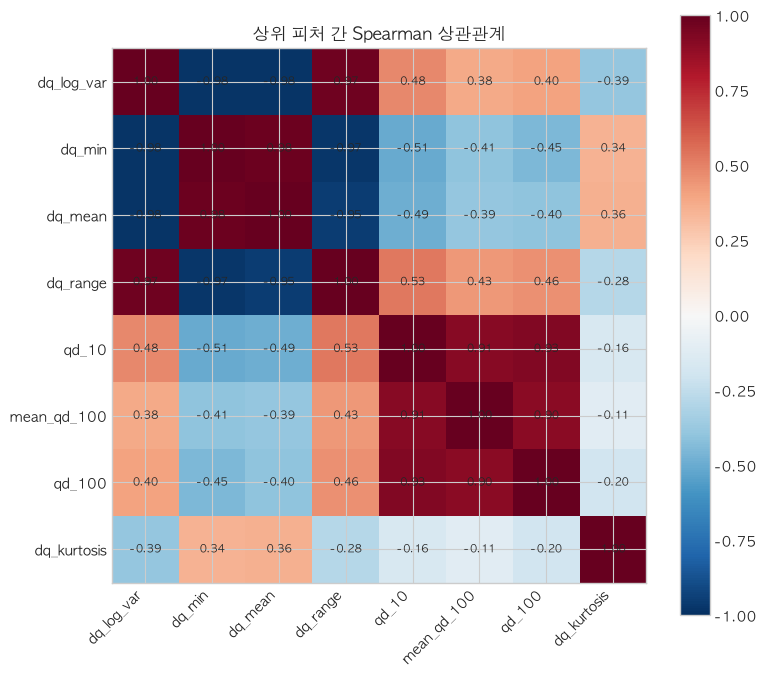

In [14]:
# 상위 피처 간 다중공선성 확인
features = corr.head(8).feature.tolist()
matrix = df[features].corr(method='spearman')
display(matrix.round(2))

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(matrix, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(features)), features, rotation=45, ha='right')
ax.set_yticks(range(len(features)), features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f'{matrix.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); plt.title('상위 피처 간 Spearman 상관관계'); plt.tight_layout(); plt.show()

## DAY1 결론 → 모델 전략

1. **Task**: `log(cycle_life)`을 예측하는 Regression  
2. **핵심 피처**: `dq_log_var`, `dq_min`을 중심으로 중복 피처 선택 또는 ElasticNet 정규화  
3. **보조 피처**: 초기 Qd 변화율, IR 변화, 온도, 충전시간, 충전정책  
4. **분할**: Batch 1 학습·검증, Batch 2 최종 Test; 동일 충전정책 누수를 막는 Group split  
5. **후보 모델**: ElasticNet 기준 모델 → Huber/Ridge → Random Forest·Gradient Boosting 비교  
6. **평가**: MAPE를 사용하고 원논문 9.1%와 비교